<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/quantum_field_theory/qft_ch06_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Quantum Field Theory* — `qft_ch06_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QFT Ch 6 Figures — Colab Notebook
**Quantum Field Theory · Chapter 6: Non-Abelian Gauge Theory**

PSE Lab · SeoulTech · Tong (Cambridge)

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | $SU(N)$ algebra, structure constants, gauge orbit | §6.1–6.2 |
| fig02 | Yang-Mills Feynman rules, 3- and 4-gluon vertices | §6.3 |
| fig03 | QCD $\beta$-function, running $\alpha_s$, Cornell potential | §6.4–6.5 |
| fig04 | QCD phase diagram, PDFs, hadron spectrum | §6.6 |

---
## fig01 · $SU(N)$ Algebra & Gauge Orbit (§6.1–6.2)

**Left**: $SU(N)$ Lie algebra $[T^a,T^b]=if^{abc}T^c$ — Casimirs $C_F,C_A$. **Centre**: $SU(3)$ structure constants $f^{abc}$ (non-zero values). **Right**: Gauge orbit — all $A_\mu$ related by $g(x)\in SU(N)$ are physically equivalent.

  saved -> figures/ch06/fig01_sun_algebra.png


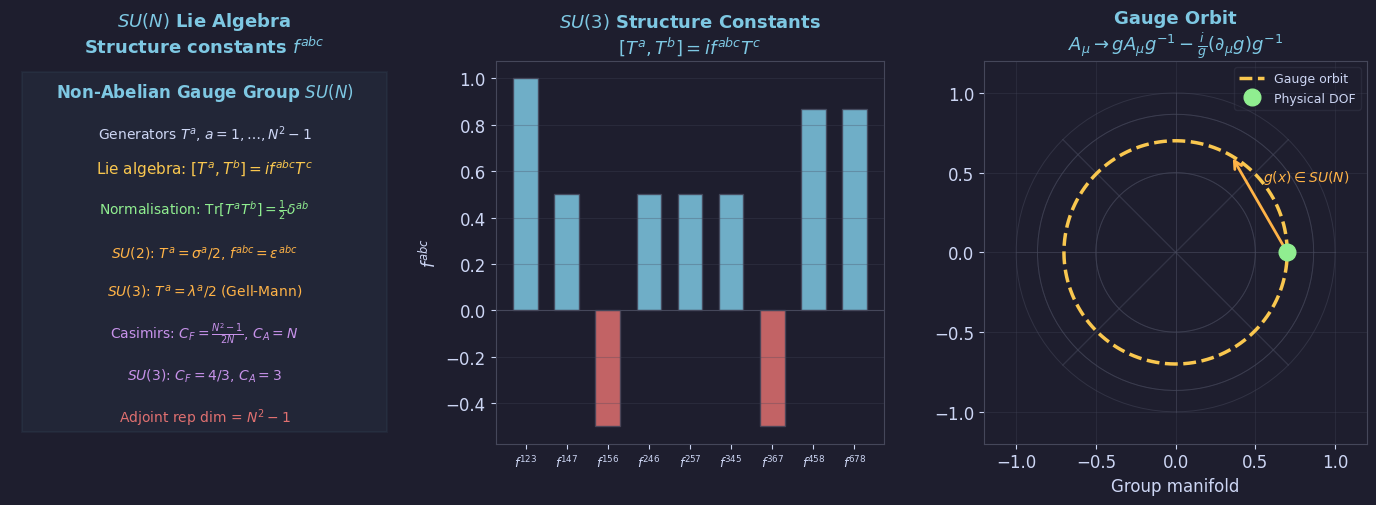

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch06'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig01: SU(N) group structure + gauge field ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: SU(N) group structure (text panel)
ax = axes[0]
ax.axis('off')
items = [
    (0.50, 0.92, 'Non-Abelian Gauge Group $SU(N)$',  BLUE,   12, 'bold'),
    (0.50, 0.81, r'Generators $T^a$, $a=1,\ldots,N^2-1$', FG, 10, 'normal'),
    (0.50, 0.72, r'Lie algebra: $[T^a,T^b]=if^{abc}T^c$', YELLOW, 11, 'normal'),
    (0.50, 0.61, r'Normalisation: $\mathrm{Tr}[T^aT^b]=\frac{1}{2}\delta^{ab}$',
     GREEN, 10, 'normal'),
    (0.50, 0.50, r'$SU(2)$: $T^a=\sigma^a/2$, $f^{abc}=\epsilon^{abc}$',
     ORANGE, 10, 'normal'),
    (0.50, 0.40, r'$SU(3)$: $T^a=\lambda^a/2$ (Gell-Mann)',
     ORANGE, 10, 'normal'),
    (0.50, 0.29, r'Casimirs: $C_F=\frac{N^2-1}{2N}$, $C_A=N$',
     PURPLE, 10, 'normal'),
    (0.50, 0.18, r'$SU(3)$: $C_F=4/3$, $C_A=3$',
     PURPLE, 10, 'normal'),
    (0.50, 0.07, r'Adjoint rep dim = $N^2-1$',
     RED, 10, 'normal'),
]
for (xp, yp, txt, col, fs, fw) in items:
    ax.text(xp, yp, txt, ha='center', va='center', color=col,
            fontsize=fs, fontweight=fw, transform=ax.transAxes)
rect = plt.Rectangle((0.03, 0.03), 0.94, 0.94, fill=True,
                      facecolor=BLUE, alpha=0.05,
                      edgecolor=BLUE, lw=1.5, transform=ax.transAxes)
ax.add_patch(rect)
ax.set_title('$SU(N)$ Lie Algebra\nStructure constants $f^{abc}$', color=BLUE)

# Centre: Structure constants f^{abc} for SU(3) (non-zero values)
ax2 = axes[1]
# Nonzero f^{abc} for SU(3)
labels = ['123','147','156','246','257','345','367','458','678']
vals   = [1.0,  0.5,  -0.5, 0.5,  0.5,  0.5,  -0.5,
          np.sqrt(3)/2, np.sqrt(3)/2]
colors_bar = [BLUE if v > 0 else RED for v in vals]
x_pos = np.arange(len(labels))
ax2.bar(x_pos, vals, color=colors_bar, edgecolor=EDGE, lw=1.0,
        alpha=0.85, width=0.6)
ax2.axhline(0, color=EDGE, lw=0.8)
ax2.set_xticks(x_pos)
ax2.set_xticklabels([r'$f^{'+l+r'}$' for l in labels], fontsize=9)
ax2.set_ylabel(r'$f^{abc}$')
ax2.set_title('$SU(3)$ Structure Constants\n' +
              r'$[T^a,T^b]=if^{abc}T^c$', color=BLUE)
ax2.grid(True, axis='y')

# Right: gauge transformation — parallel transport on group manifold (schematic)
ax3 = axes[2]
theta = np.linspace(0, 2*np.pi, 300)
# SU(2) group manifold ~ S^3, project to S^2
phi_arr = np.linspace(0, np.pi, 100)
th_arr  = np.linspace(0, 2*np.pi, 100)
# Draw S^2 as gauge orbit
for phi_v in [np.pi/6, np.pi/3, np.pi/2, 2*np.pi/3, 5*np.pi/6]:
    x_c = np.sin(phi_v)*np.cos(th_arr)
    y_c = np.sin(phi_v)*np.sin(th_arr)
    ax3.plot(x_c, y_c, color=EDGE, lw=0.7, alpha=0.5)
for th_v in np.linspace(0, 2*np.pi, 9)[:-1]:
    x_m = np.sin(phi_arr)*np.cos(th_v)
    y_m = np.sin(phi_arr)*np.sin(th_v)
    ax3.plot(x_m, y_m, color=EDGE, lw=0.7, alpha=0.5)
# Gauge orbit
circ_r = 0.7
ax3.plot(circ_r*np.cos(theta), circ_r*np.sin(theta),
         color=YELLOW, lw=2.5, ls='--', label='Gauge orbit')
# Physical point
ax3.plot([0.7], [0.0], 'o', color=GREEN, ms=12, zorder=6, label='Physical DOF')
# Gauge transformation arrow
ax3.annotate('', xy=(circ_r*np.cos(np.pi/3), circ_r*np.sin(np.pi/3)),
             xytext=(0.7, 0.0),
             arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.0, mutation_scale=14))
ax3.text(0.55, 0.45, r'$g(x)\in SU(N)$', color=ORANGE, fontsize=10)
ax3.set_xlabel(r'Group manifold'); ax3.set_ylabel('')
ax3.set_title('Gauge Orbit\n' + r'$A_\mu\to gA_\mu g^{-1}-\frac{i}{g}(\partial_\mu g)g^{-1}$',
              color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(-1.2, 1.2); ax3.set_ylim(-1.2, 1.2); ax3.set_aspect('equal')

plt.tight_layout(pad=1.2)
save('fig01_sun_algebra.png', fig)


---
## fig02 · Yang-Mills Feynman Rules (§6.3)

**Left**: Yang-Mills Feynman rules — gluon propagator, 3-gluon, 4-gluon, quark-gluon vertices. **Centre**: 3-gluon vertex $\sim gf^{abc}$ — gluons self-interact (no QED analogue). **Right**: 4-gluon vertex $\sim g^2f^{abe}f^{cde}$ — unique to non-Abelian theories.

  saved -> figures/ch06/fig02_vertices.png


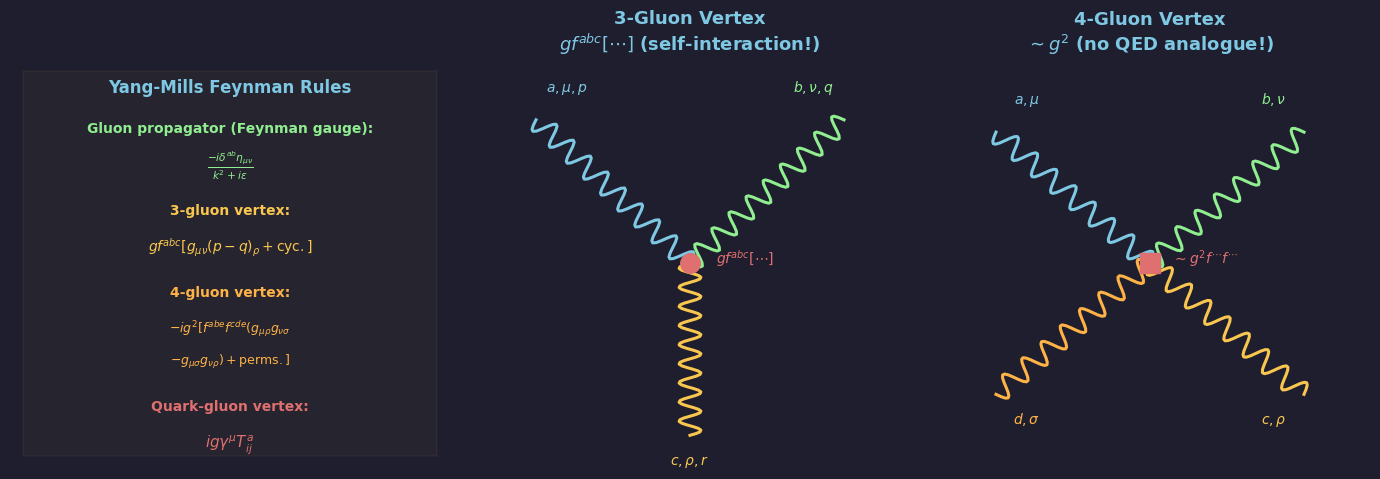

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch06'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig02: Yang-Mills Feynman rules (3- and 4-gluon vertices) ────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Yang-Mills Feynman rules (text panel)
ax = axes[0]
ax.axis('off')
items = [
    (0.50, 0.93, 'Yang-Mills Feynman Rules',                               BLUE,   12, 'bold'),
    (0.50, 0.83, 'Gluon propagator (Feynman gauge):',                     GREEN,  10, 'bold'),
    (0.50, 0.74, r'$\frac{-i\delta^{ab}\eta_{\mu\nu}}{k^2+i\varepsilon}$',GREEN, 11, 'normal'),
    (0.50, 0.63, '3-gluon vertex:',                                        YELLOW, 10, 'bold'),
    (0.50, 0.54, r'$gf^{abc}[g_{\mu\nu}(p-q)_\rho+\mathrm{cyc.}]$',      YELLOW, 10, 'normal'),
    (0.50, 0.43, '4-gluon vertex:',                                        ORANGE, 10, 'bold'),
    (0.50, 0.34, r'$-ig^2[f^{abe}f^{cde}(g_{\mu\rho}g_{\nu\sigma}$',     ORANGE, 9, 'normal'),
    (0.50, 0.26, r'$-g_{\mu\sigma}g_{\nu\rho})+\mathrm{perms.}]$',        ORANGE, 9, 'normal'),
    (0.50, 0.15, 'Quark-gluon vertex:',                                    RED,    10, 'bold'),
    (0.50, 0.06, r'$ig\gamma^\mu T^a_{ij}$',                              RED,    11, 'normal'),
]
for (xp, yp, txt, col, fs, fw) in items:
    ax.text(xp, yp, txt, ha='center', va='center', color=col,
            fontsize=fs, fontweight=fw, transform=ax.transAxes)
rect = plt.Rectangle((0.03, 0.03), 0.94, 0.94, fill=True,
                      facecolor=YELLOW, alpha=0.04,
                      edgecolor=YELLOW, lw=1.5, transform=ax.transAxes)
ax.add_patch(rect)
#ax.set_title('Yang-Mills Feynman Rules', color=BLUE)

# Centre: 3-gluon vertex diagram
ax2 = axes[1]
ax2.axis('off')
cx, cy = 0.50, 0.50
legs3 = [(0.15, 0.85), (0.85, 0.85), (0.50, 0.08)]
colors3 = [BLUE, GREEN, YELLOW]
labels3 = [r'$a,\mu,p$', r'$b,\nu,q$', r'$c,\rho,r$']
for (lx, ly), col, lab in zip(legs3, colors3, labels3):
    # wavy line
    t_wav = np.linspace(0, 1, 100)
    x_w = lx + (cx-lx)*t_wav
    y_w = ly + (cy-ly)*t_wav
    amp = 0.025; freq = 18
    perp_x = -(ly-cy); perp_y = (lx-cx)
    norm = np.sqrt(perp_x**2+perp_y**2)+1e-9
    perp_x /= norm; perp_y /= norm
    x_w2 = x_w + perp_x*amp*np.sin(freq*np.pi*t_wav)
    y_w2 = y_w + perp_y*amp*np.sin(freq*np.pi*t_wav)
    ax2.plot(x_w2, y_w2, color=col, lw=2.2, transform=ax2.transAxes)
    dx = 0.07*np.sign(lx-cx); dy = 0.07*np.sign(ly-cy)
    ax2.text(lx-dx, ly+dy, lab, ha='center', color=col,
             fontsize=10, transform=ax2.transAxes)
ax2.plot(cx, cy, 'o', color=RED, ms=14, transform=ax2.transAxes, zorder=5)
ax2.text(cx+0.06, cy, r'$gf^{abc}[\cdots]$',
         color=RED, fontsize=10, transform=ax2.transAxes)
ax2.set_title('3-Gluon Vertex\n' + r'$gf^{abc}[\cdots]$ (self-interaction!)',
              color=BLUE)

# Right: 4-gluon vertex diagram
ax3 = axes[2]
ax3.axis('off')
cx3, cy3 = 0.50, 0.50
legs4 = [(0.15,0.82),(0.85,0.82),(0.85,0.18),(0.15,0.18)]
cols4 = [BLUE, GREEN, YELLOW, ORANGE]
labs4 = [r'$a,\mu$', r'$b,\nu$', r'$c,\rho$', r'$d,\sigma$']
for (lx, ly), col, lab in zip(legs4, cols4, labs4):
    t_wav = np.linspace(0, 1, 100)
    x_w = lx + (cx3-lx)*t_wav
    y_w = ly + (cy3-ly)*t_wav
    amp = 0.025; freq = 16
    perp_x = -(ly-cy3); perp_y = (lx-cx3)
    norm = np.sqrt(perp_x**2+perp_y**2)+1e-9
    perp_x /= norm; perp_y /= norm
    x_w2 = x_w + perp_x*amp*np.sin(freq*np.pi*t_wav)
    y_w2 = y_w + perp_y*amp*np.sin(freq*np.pi*t_wav)
    ax3.plot(x_w2, y_w2, color=col, lw=2.2, transform=ax3.transAxes)
    dx = 0.07*np.sign(lx-cx3); dy = 0.07*np.sign(ly-cy3)
    ax3.text(lx-dx, ly+dy, lab, ha='center', color=col,
             fontsize=10, transform=ax3.transAxes)
ax3.plot(cx3, cy3, 's', color=RED, ms=14, transform=ax3.transAxes, zorder=5)
ax3.text(cx3+0.05, cy3, r'$\sim g^2f^{\cdots}f^{\cdots}$',
         color=RED, fontsize=10, transform=ax3.transAxes)
ax3.set_title('4-Gluon Vertex\n' + r'$\sim g^2$ (no QED analogue!)', color=BLUE)

plt.tight_layout(pad=1.2)
save('fig02_vertices.png', fig)


---
## fig03 · Asymptotic Freedom & Confinement (§6.4–6.5)

**Left**: QCD $\beta$-function $\beta_0=(11N_c-2N_f)/12\pi>0$ — negative $\beta(g)$, UV free. **Centre**: Running $\alpha_s(\mu)$ with experimental data — asymptotic freedom. **Right**: Cornell potential $V=-4\alpha_s/3r+\sigma r$ — Coulomb + linear confinement.

  saved -> figures/ch06/fig03_asymptotic_freedom.png


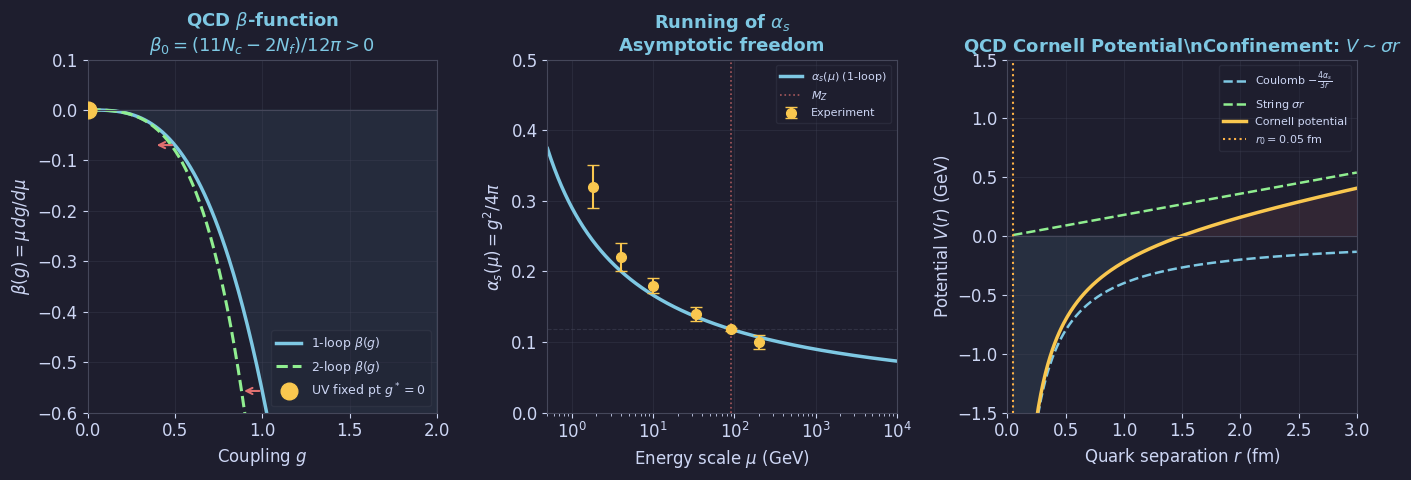

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch06'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig03: Asymptotic freedom + beta function ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: QCD beta function b0, b1
ax = axes[0]
g_arr = np.linspace(0.01, 2.0, 300)
N_c = 3; N_f = 6
b0 = (11*N_c - 2*N_f) / (12*np.pi)   # > 0 for N_f < 33/2
b1 = (34*N_c**2 - 10*N_c*N_f - 3*(N_c**2-1)*N_f/N_c) / (24*np.pi**2)
beta_1loop = -b0 * g_arr**3
beta_2loop = -b0 * g_arr**3 - b1 * g_arr**5
ax.plot(g_arr, beta_1loop, color=BLUE,   lw=2.5, label=r'1-loop $\beta(g)$')
ax.plot(g_arr, beta_2loop, color=GREEN,  lw=2.2, ls='--', label=r'2-loop $\beta(g)$')
ax.axhline(0, color=EDGE, lw=0.8)
ax.plot([0], [0], 'o', color=YELLOW, ms=12, zorder=5, label=r'UV fixed pt $g^*=0$')
for gv in [0.5, 1.0, 1.5]:
    bv = -b0*gv**3
    ax.annotate('', xy=(gv-0.12, bv), xytext=(gv, bv),
                arrowprops=dict(arrowstyle='->', color=RED, lw=1.5, mutation_scale=11))
ax.fill_between(g_arr, beta_1loop, 0, color=BLUE, alpha=0.08)
ax.set_xlabel(r'Coupling $g$')
ax.set_ylabel(r'$\beta(g)=\mu\,dg/d\mu$')
ax.set_title(r'QCD $\beta$-function' + '\n' +
             r'$\beta_0=(11N_c-2N_f)/12\pi>0$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0, 2); ax.set_ylim(-0.6, 0.1)

# Centre: running alpha_s vs energy scale
ax2 = axes[1]
mu_arr = np.logspace(np.log10(0.5), 4, 400)
alpha_s0 = 0.118; mu0 = 91.2
b0_val = (11*3 - 2*6)/(12*np.pi)
# 1-loop running
alpha_s = alpha_s0 / (1 + alpha_s0 * 2*b0_val * np.log(mu_arr/mu0))
alpha_s = np.where(alpha_s < 0, np.nan, alpha_s)
alpha_s = np.where(alpha_s > 2,  np.nan, alpha_s)
ax2.plot(mu_arr, alpha_s, color=BLUE, lw=2.5,
         label=r'$\alpha_s(\mu)$ (1-loop)')
# Experimental points (approximate)
exp_mu  = [1.8,   4.0,  10.0,  34.0, 91.2, 200.]
exp_as  = [0.32,  0.22,  0.18,  0.14, 0.118, 0.10]
exp_err = [0.03,  0.02,  0.01,  0.01, 0.002, 0.01]
ax2.errorbar(exp_mu, exp_as, yerr=exp_err, fmt='o', color=YELLOW,
             ms=7, capsize=4, elinewidth=1.5, label='Experiment')
ax2.axvline(91.2, color=RED, lw=1.2, ls=':', alpha=0.7, label=r'$M_Z$')
ax2.axhline(alpha_s0, color=EDGE, lw=0.8, ls='--', alpha=0.5)
ax2.set_xscale('log')
ax2.set_xlabel(r'Energy scale $\mu$ (GeV)')
ax2.set_ylabel(r'$\alpha_s(\mu)=g^2/4\pi$')
ax2.set_title('Running of $\\alpha_s$\nAsymptotic freedom', color=BLUE)
ax2.legend(fontsize=8, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0.5, 1e4); ax2.set_ylim(0, 0.5)

# Right: confinement — string potential
ax3 = axes[2]
r_arr = np.linspace(0.05, 3.0, 300)
# QCD potential: Coulomb at short range + linear confinement
alpha_s_r = 0.3
V_coulomb = -4/3 * alpha_s_r / r_arr
V_string  = 0.18 * r_arr          # string tension sigma ~ 0.18 GeV^2
V_total   = V_coulomb + V_string
ax3.plot(r_arr, V_coulomb, color=BLUE,   lw=1.8, ls='--',
         label=r'Coulomb $-\frac{4\alpha_s}{3r}$')
ax3.plot(r_arr, V_string,  color=GREEN,  lw=1.8, ls='--',
         label=r'String $\sigma r$')
ax3.plot(r_arr, V_total,   color=YELLOW, lw=2.5,
         label=r'Cornell potential')
ax3.axhline(0, color=EDGE, lw=0.8)
ax3.fill_between(r_arr, V_total, 0,
                 where=(V_total < 0), color=BLUE,  alpha=0.10)
ax3.fill_between(r_arr, V_total, 0,
                 where=(V_total > 0), color=RED,   alpha=0.10)
r_min = r_arr[np.argmin(V_total)]
ax3.axvline(r_min, color=ORANGE, lw=1.5, ls=':', label=f'$r_0={r_min:.2f}$ fm')
ax3.set_xlabel(r'Quark separation $r$ (fm)')
ax3.set_ylabel(r'Potential $V(r)$ (GeV)')
ax3.set_title(r'QCD Cornell Potential\nConfinement: $V\sim\sigma r$', color=BLUE)
ax3.legend(fontsize=8, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0, 3); ax3.set_ylim(-1.5, 1.5)

plt.tight_layout(pad=1.2)
save('fig03_asymptotic_freedom.png', fig)


---
## fig04 · QCD Phenomenology (§6.6)

**Left**: QCD phase diagram — hadronic, QGP, and colour superconducting phases; CEP. **Centre**: Parton distribution functions $xf(x,Q^2)$ — valence quarks at $x\sim1/3$, gluon dominates at small $x$. **Right**: Hadron spectrum — mesons and baryons confined from quarks and gluons.

  saved -> figures/ch06/fig04_qcd_pheno.png


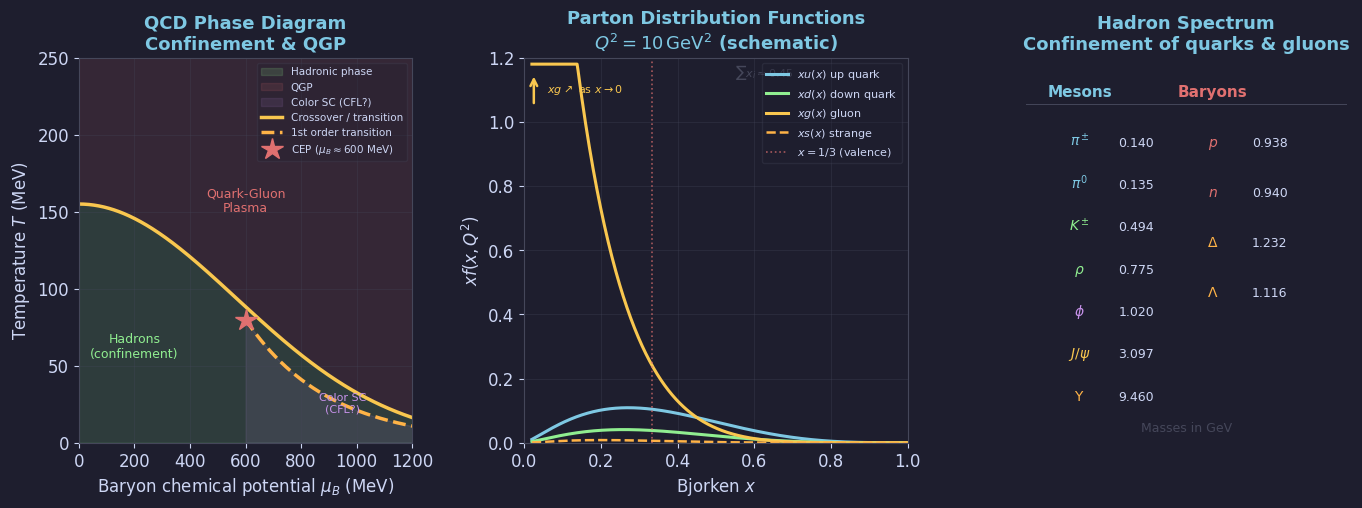

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.integrate import trapezoid
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch06'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig04: QCD phases + DIS structure functions ────────────────────────────
fig = plt.figure(figsize=(14, 5))
fig.patch.set_facecolor(BG)

# [위치 수정] 2번째 패널을 3번째 방향으로 시각적 이동
# width_ratios=[1.0, 1.15, 1.0] + wspace=0.32로 1↔2 간격을 상대적으로 넓힘
gs = gridspec.GridSpec(1, 3, figure=fig,
                       width_ratios=[1.0, 1.15, 1.0],
                       left=0.06, right=0.97,
                       wspace=0.32)
ax, ax2, ax3 = [fig.add_subplot(gs[i]) for i in range(3)]

# ── Left: QCD Phase Diagram (T vs mu_B) ───────────────────────────────────
mu_B = np.linspace(0, 1200, 400)
T_cross = 155 * np.exp(-((mu_B)/800)**2)   # crossover T ~ 155 MeV (lattice QCD)
mu_cep = 600; T_cep = 80                   # CEP: schematic
mu_1st = np.linspace(mu_cep, 1200, 200)
T_1st  = T_cep * np.exp(-(mu_1st - mu_cep)/300)

ax.fill_between(mu_B, 0, T_cross, color=GREEN, alpha=0.15, label='Hadronic phase')
ax.fill_between(mu_B, T_cross, 250, color=RED, alpha=0.12, label='QGP')
# Color SC 영역: 1차 상전이선 아래, 고 μ_B
mu_sc = np.linspace(mu_cep, 1200, 200)
ax.fill_between(mu_sc, 0, T_1st, color=PURPLE, alpha=0.10, label='Color SC (CFL?)')
ax.plot(mu_B, T_cross, color=YELLOW, lw=2.5, label='Crossover / transition')
ax.plot(mu_1st, T_1st, color=ORANGE, lw=2.5, ls='--', label='1st order transition')
ax.plot([mu_cep], [T_cep], '*', color=RED, ms=16, zorder=6,
        label=f'CEP ($\\mu_B\\approx{mu_cep}$ MeV)')
ax.text(200, 55,  'Hadrons\n(confinement)', ha='center', color=GREEN,  fontsize=9)
ax.text(600, 150, 'Quark-Gluon\nPlasma',   ha='center', color=RED,    fontsize=9)
ax.text(950, 20,  'Color SC\n(CFL?)',       ha='center', color=PURPLE, fontsize=8)
ax.set_xlabel(r'Baryon chemical potential $\mu_B$ (MeV)')
ax.set_ylabel(r'Temperature $T$ (MeV)')
ax.set_title('QCD Phase Diagram\n' + r'Confinement & QGP', color=BLUE)
ax.legend(fontsize=7.5, labelcolor=FG, loc='upper right'); ax.grid(True)
ax.set_xlim(0, 1200); ax.set_ylim(0, 250)

# ── Centre: Parton Distribution Functions ─────────────────────────────────
# x 범위: 0.02~1 (소 x 발산 표현, 극단적 확대 없이)
x_bj = np.linspace(0.02, 1.0, 400)

# Valence quarks: xf(x) = A * x^a * (1-x)^b (CTEQ 스타일, 정성적)
u_val = 1.8  * x_bj**0.3  * (1-x_bj)**3.5   # xu(x): u 쿼크 우세
d_val = 0.9  * x_bj**0.4  * (1-x_bj)**4.0   # xd(x): d 쿼크 (u의 절반)

# [수정] 글루온 xg(x): 소 x에서 상승하는 물리적으로 올바른 형태
# xg(x) = A * x^{-δ} * (1-x)^n, δ=0.2 (완만한 소 x 상승)
# 이전 코드의 버그: x^{-0.3}*x = x^{0.7} → 소 x에서 감소 (틀림!)
# 수정: xg(x)를 직접 정의 → 소 x에서 올바르게 발산
g_xg  = 1.8  * x_bj**(-0.2) * (1-x_bj)**5.5  # xg(x): 소 x 상승 ✓

# Sea quarks (strange)
s_pdf = 0.35 * x_bj**0.5  * (1-x_bj)**6.0    # xs(x)

# ylim=1.2 초과하는 글루온은 클리핑 + 화살표로 암시
g_clip = np.minimum(g_xg, 1.18)

ax2.plot(x_bj, x_bj*u_val, color=BLUE,   lw=2.2, label=r'$xu(x)$ up quark')
ax2.plot(x_bj, x_bj*d_val, color=GREEN,  lw=2.2, label=r'$xd(x)$ down quark')
ax2.plot(x_bj, g_clip,     color=YELLOW, lw=2.2, label=r'$xg(x)$ gluon')
ax2.plot(x_bj, x_bj*s_pdf, color=ORANGE, lw=1.8, ls='--', label=r'$xs(x)$ strange')
ax2.axvline(1/3, color=RED, lw=1.2, ls=':', alpha=0.7, label=r'$x=1/3$ (valence)')
# 글루온의 소 x 발산을 화살표로 암시
ax2.annotate('', xy=(0.025, 1.15), xytext=(0.025, 1.05),
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.8))
ax2.text(0.06, 1.10, r'$xg\nearrow$ as $x\to0$',
         color=YELLOW, fontsize=8, va='center')
# Momentum fraction 합 표시
mom_u = trapezoid(x_bj*u_val, x_bj)
mom_d = trapezoid(x_bj*d_val, x_bj)
mom_g = trapezoid(g_xg,       x_bj)
mom_s = trapezoid(x_bj*s_pdf, x_bj)
total = mom_u + mom_d + mom_g + 2*mom_s
ax2.text(0.55, 0.95, f'$\\sum x_i\\approx{total:.2f}$',
         transform=ax2.transAxes, color=EDGE, fontsize=8, ha='left')
ax2.set_xlabel(r'Bjorken $x$')
ax2.set_ylabel(r'$xf(x,Q^2)$')
ax2.set_title('Parton Distribution Functions\n' +
              r'$Q^2=10\,\mathrm{GeV}^2$ (schematic)', color=BLUE)
ax2.legend(fontsize=8, labelcolor=FG, loc='upper right')
ax2.grid(True)
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1.2)

# ── Right: Hadron Spectrum ─────────────────────────────────────────────────
ax3.axis('off')
hadrons = [
    # (name, mass_GeV, type, color) — PDG 2022 masses
    (r'$\pi^\pm$',  0.140, 'meson',  BLUE),
    (r'$\pi^0$',    0.135, 'meson',  BLUE),
    (r'$K^\pm$',    0.494, 'meson',  GREEN),
    (r'$\rho$',     0.775, 'meson',  GREEN),
    (r'$\phi$',     1.020, 'meson',  PURPLE),
    (r'$J/\psi$',   3.097, 'meson',  YELLOW),
    (r'$\Upsilon$', 9.460, 'meson',  ORANGE),
    (r'$p$',        0.938, 'baryon', RED),
    (r'$n$',        0.940, 'baryon', RED),
    (r'$\Delta$',   1.232, 'baryon', ORANGE),
    (r'$\Lambda$',  1.116, 'baryon', ORANGE),
]
x_m = 0.18; x_b = 0.58
ax3.text(x_m, 0.90, 'Mesons',  ha='center', color=BLUE, fontsize=11,
         fontweight='bold', transform=ax3.transAxes)
ax3.text(x_b, 0.90, 'Baryons', ha='center', color=RED,  fontsize=11,
         fontweight='bold', transform=ax3.transAxes)
ax3.plot([0.02,0.98],[0.88,0.88], color=EDGE, lw=0.7, transform=ax3.transAxes)
mesons  = [(n,m,c) for n,m,t,c in hadrons if t=='meson']
baryons = [(n,m,c) for n,m,t,c in hadrons if t=='baryon']
for i,(name,mass,col) in enumerate(mesons):
    yp = 0.77 - i*0.11
    ax3.text(x_m,      yp, name,          ha='center', color=col,
             fontsize=10, transform=ax3.transAxes)
    ax3.text(x_m+0.17, yp, f'{mass:.3f}', ha='center', color=FG,
             fontsize=9,  transform=ax3.transAxes)
for i,(name,mass,col) in enumerate(baryons):
    yp = 0.77 - i*0.13
    ax3.text(x_b,      yp, name,          ha='center', color=col,
             fontsize=10, transform=ax3.transAxes)
    ax3.text(x_b+0.17, yp, f'{mass:.3f}', ha='center', color=FG,
             fontsize=9,  transform=ax3.transAxes)
ax3.text(0.50, 0.03, 'Masses in GeV', ha='center', color=EDGE,
         fontsize=9, transform=ax3.transAxes)
ax3.set_title('Hadron Spectrum\nConfinement of quarks & gluons', color=BLUE)

save('fig04_qcd_pheno.png', fig)

---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

# AUTO-INJECTED: Korean font setup for matplotlib
import os as _os
import matplotlib.font_manager as _fm
import matplotlib.pyplot as _plt
if not any('NanumGothic' in f.name for f in _fm.fontManager.ttflist):
    for _font in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
                  '/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf']:
        if _os.path.exists(_font):
            _fm.fontManager.addfont(_font)
_plt.rcParams.update({'font.family': 'NanumGothic', 'axes.unicode_minus': False})
del _os, _fm, _plt
# END AUTO-INJECTED Korean font setup


OUTDIR = 'figures/ch06'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')])
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name = 'qft_ch06_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 4 figures:
  fig01_sun_algebra.png  (200 KB)
  fig02_vertices.png  (166 KB)
  fig03_asymptotic_freedom.png  (201 KB)
  fig04_qcd_pheno.png  (233 KB)
Zip: qft_ch06_figures.zip  (757 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>